# Agentic AI Radar — Stage 3: Text and Knowledge-Graph RAG

**Research question:** Does bounded co-mention graph expansion improve retrieval-grounded answers about the Agentic Web compared with the same text-only baseline?

This notebook implements a reproducible text-only TF–IDF retriever and a graph-expanded variant over the existing Agentic Web corpus. It uses the existing Stage 1 data and graph **read-only**. The graph used for expansion contains only `MENTIONED_WITH` co-occurrence edges; those edges are retrieval cues, never factual claims. The other semantic-claim export is not used because its claims are marked unreviewed candidates. Answers must be supported by retrieved article text and cite article IDs.

The professor's Stage 3 brief requires a track-focused passage set, approximately 200–300 Q&A pairs authored by an LLM different from the RAG answer model, manual Q&A review, text-only and graph-KG comparison, a tested enhancement, evaluation, and a documented notebook. Generated questions remain candidates until a human reviews them. This notebook will not fabricate review labels or final metrics.

**Models and API guard:** `gpt-4o-mini` drafts questions; `gpt-4o` answers both variants. The combined API spend guard is **$10 USD**, with actual token usage recorded. OpenAI calls are disabled by default and only run when the explicit flags below are enabled. The current Stage 2 notebook-package item remains separate and open. No Stage 1 files or artifacts are modified.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "data/processed/agentic_subset.parquet").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository or a child directory.")
sys.path.insert(0, str(ROOT))

from stage3_rag import (
    API_BUDGET_USD,
    ANSWER_MODEL,
    AUTHORING_MODEL,
    TfidfGraphRetriever,
    answer_reviews_complete,
    answer_quality_metrics,
    approved_questions,
    cooccurrence_reviews_complete,
    freeze_question_splits,
    generate_question_candidates,
    load_agentic_corpus,
    load_cooccurrence_graph,
    load_openai_client,
    passage_manifest,
    retrieval_metrics,
    run_paired_answers,
    run_paired_retrieval,
    sample_passages,
)

PASSAGE_COUNT = 100
PASSAGE_SEED = 20261020
PASSAGE_CHARS = 2400
TOP_K = 5
RUN_QUESTION_GENERATION = False
RUN_PAIRED_ANSWER_EVALUATION = False

EVALUATIONS = ROOT / "outputs/evaluations"
FIGURES = ROOT / "outputs/figures"
TABLES = ROOT / "outputs/tables"
for directory in (EVALUATIONS, FIGURES, TABLES):
    directory.mkdir(parents=True, exist_ok=True)

print("Repository:", ROOT)
print("Question authoring model:", AUTHORING_MODEL)
print("Paired answer model:", ANSWER_MODEL)
print(f"Combined API budget cap: ${API_BUDGET_USD:.2f}")

Repository: /Users/kushtrimbytyqi/Desktop/Computational Language Technologies
Question authoring model: gpt-4o-mini
Paired answer model: gpt-4o
Combined API budget cap: $10.00


## 1. Read-only inputs and validation

The retrieval corpus is the existing Agentic Web subset. The co-occurrence graph is used only to expand candidate article IDs; answer evidence always comes from article text. The separate semantic-claim graph was inspected read-only and its 496 edges are all marked `unreviewed_candidate`, so it is excluded from factual answering.

In [2]:
articles = load_agentic_corpus(ROOT)
graph = load_cooccurrence_graph(ROOT)

linked_article_ids = set()
for _, _, edge in graph.edges(data=True):
    values = edge.get("article_ids", "[]")
    linked_article_ids.update(map(str, json.loads(values) if isinstance(values, str) else values))
corpus_ids = set(articles["article_id"].astype(str))

print("Agentic Web articles:", len(articles))
print("Unique article IDs:", articles["article_id"].nunique())
print("Articles with parsed publication dates:", int(articles["published_at"].notna().sum()))
print("Date range:", articles["published_at"].min(), "to", articles["published_at"].max())
print("Read-only graph:", graph.number_of_nodes(), "entities and", graph.number_of_edges(), "co-occurrence edges")
print("Graph-linked article IDs:", len(linked_article_ids), "overlap with corpus:", len(linked_article_ids & corpus_ids))
if linked_article_ids - corpus_ids:
    raise ValueError("The graph contains article IDs absent from the selected-track corpus.")

Agentic Web articles: 11867
Unique article IDs: 11867
Articles with parsed publication dates: 11867
Date range: 2024-09-11 00:00:00+00:00 to 2026-08-31 00:00:00+00:00
Read-only graph: 8183 entities and 31817 co-occurrence edges
Graph-linked article IDs: 8735 overlap with corpus: 8735


## 2. Freeze a representative passage sample

The 100 passages are sampled without replacement and stratified by publication quarter and the existing `topic_id` field. The IDs are retained with character offsets so source excerpts can be reconstructed from the read-only corpus. The exported manifest omits article text; the corpus remains the source of truth. Topic IDs are used only for sample coverage, not interpreted as validated topic labels.

Sampled passages: 100 unique articles: 100
By publication quarter:


,passages
quarter,
2024Q3,2
2024Q4,5
2025Q1,11
2025Q2,12
2025Q3,10
2025Q4,12
2026Q1,14
2026Q2,25
2026Q3,9


By existing topic_id (coverage only):


,passages
topic_id,
0,33
1,33
2,34


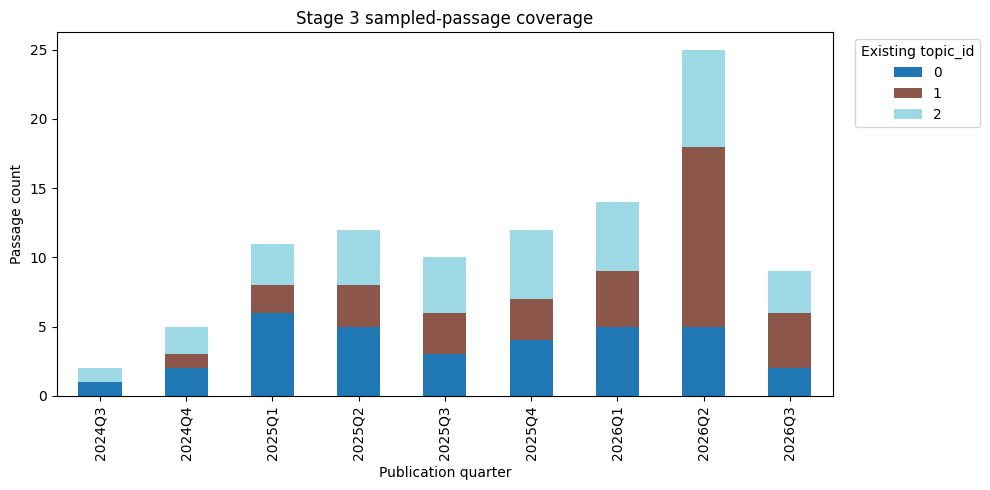

Saved: outputs/figures/stage3_passage_sample_coverage.png


In [3]:
passages = sample_passages(
    articles,
    sample_size=PASSAGE_COUNT,
    seed=PASSAGE_SEED,
    passage_chars=PASSAGE_CHARS,
)
manifest = passage_manifest(passages)
passages_path = EVALUATIONS / "stage3_passages.csv"

if passages_path.exists():
    saved_manifest = pd.read_csv(passages_path)
    if saved_manifest["passage_id"].astype(str).tolist() != manifest["passage_id"].astype(str).tolist():
        raise ValueError("Saved passage manifest differs from the frozen deterministic sample.")
else:
    manifest.to_csv(passages_path, index=False)

print("Sampled passages:", len(passages), "unique articles:", passages["article_id"].nunique())
print("By publication quarter:")
display(passages.groupby("quarter").size().rename("passages").to_frame())
print("By existing topic_id (coverage only):")
display(passages.groupby("topic_id", dropna=False).size().rename("passages").to_frame())

coverage = passages.pivot_table(
    index="quarter", columns="topic_id", values="passage_id", aggfunc="count", fill_value=0
)
ax = coverage.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab20")
ax.set(title="Stage 3 sampled-passage coverage", xlabel="Publication quarter", ylabel="Passage count")
ax.legend(title="Existing topic_id", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
coverage_path = FIGURES / "stage3_passage_sample_coverage.png"
plt.savefig(coverage_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", coverage_path.relative_to(ROOT))

## 3. Draft Q&A candidates — human review required

The formal brief calls for approximately 100–150 representative passages and approximately 200–300 Q&A pairs, typically 1–3 per passage. This workflow drafts two candidates per passage using `gpt-4o-mini`, distinct from the `gpt-4o` answer model. Only the selected 2,400-character excerpt, title, and available publication date are sent for each passage. The generated `reference_answer` and quote are not gold labels until reviewed.

To incur API cost, explicitly set `RUN_QUESTION_GENERATION = True` and run the next cell. Usage and estimated spend are checkpointed to `outputs/evaluations/stage3_api_usage.csv`; the code stops before a call if its conservative estimate would exceed the $10 cap. Generated rows start with `review_status='pending'`. No answer-generation or final evaluation calls are made before manual review.

In [4]:
questions_path = EVALUATIONS / "stage3_questions.csv"
usage_path = EVALUATIONS / "stage3_api_usage.csv"

if RUN_QUESTION_GENERATION:
    client = load_openai_client(ROOT)
    questions = generate_question_candidates(
        passages,
        client,
        questions_path,
        usage_path,
        budget_usd=API_BUDGET_USD,
    )
    print("Candidate questions saved:", len(questions))
elif questions_path.exists():
    questions = pd.read_csv(questions_path)
    print("Loaded saved candidate questions:", len(questions))
else:
    questions = pd.DataFrame()
    print("Question generation is disabled. No API call was made.")

Loaded saved candidate questions: 200


## 4. Freeze splits and inspect review status

Questions are split by source passage so two questions from the same article cannot leak across development and test partitions. The automated `evidence_quote_matches_passage` flag is only a whitespace-normalized substring check, not human validation; a false flag requires correcting the quote or rejecting the item. Review every candidate against the cited article excerpt before confirmatory evaluation:

- Set `review_status` to `approved` only if the question, reference answer, question type, and evidence quote are supported and clear.
- Set `review_status` to `rejected` for invalid or unanswerable candidates; provide `reviewer_id` and a brief `review_notes` reason.
- If correcting a candidate, edit the fields and document the correction before marking it approved.
- Do not change a question after the frozen test split without recording and refreezing the set.

In [5]:
if not questions.empty:
    frozen_questions = freeze_question_splits(questions, test_size=0.30, seed=PASSAGE_SEED)
    if "split" in questions and not questions["split"].fillna("").astype(str).eq(
        frozen_questions["split"].astype(str)
    ).all():
        raise ValueError("Saved question split differs from the deterministic passage-group split.")
    questions = frozen_questions
    questions.to_csv(questions_path, index=False)
    split_manifest_path = EVALUATIONS / "stage3_question_splits.csv"
    questions[["question_id", "passage_id", "split"]].to_csv(split_manifest_path, index=False)
    print("Saved split manifest:", split_manifest_path.relative_to(ROOT))
    print("Questions by split and type:")
    display(pd.crosstab(questions["split"], questions["question_type"]))
    print("Review status:")
    display(questions["review_status"].value_counts(dropna=False).rename_axis("status").to_frame("count"))
    if "evidence_quote_matches_passage" in questions:
        evidence_matches = questions["evidence_quote_matches_passage"].fillna(False).astype(bool)
        print(f"Automated evidence-quote substring matches: {int(evidence_matches.sum())}/{len(questions)}; this is not a human review.")
else:
    print("No questions are available to split or review yet.")

Saved split manifest: outputs/evaluations/stage3_question_splits.csv
Questions by split and type:


question_type,analytical,comparative,factoid,relational,temporal
split,,,,,
development,30,26,30,26,28
test,10,15,11,13,11


Review status:


,count
status,
pending,200


Automated evidence-quote substring matches: 115/200; this is not a human review.


## 5. Text-only and graph-expanded retrieval

The baseline is TF–IDF over article titles and full cleaned texts. The graph variant adds a bounded set of article IDs linked through `MENTIONED_WITH` edges for entities matched in the query, then reranks the union using lexical similarity plus a fixed graph-support weight. The graph never supplies a factual answer; the generator receives only retrieved article passages and must cite their IDs. The comparison is diagnostic until Q&A candidates are human-reviewed.

In [6]:
retriever = TfidfGraphRetriever(articles, graph, max_features=200_000)
print("TF–IDF index shape:", retriever.matrix.shape, "non-zero values:", retriever.matrix.nnz)

if not questions.empty:
    retrieval_diagnostics = run_paired_retrieval(questions, retriever, top_k=TOP_K)
    retrieval_diagnostics["question_review_state"] = "pending_or_unverified"
    diagnostics_path = EVALUATIONS / "stage3_retrieval_diagnostics.csv"
    retrieval_diagnostics.to_csv(diagnostics_path, index=False)
    print("Saved provisional retrieval diagnostics:", diagnostics_path.relative_to(ROOT))
    display(retrieval_diagnostics.head(6))
else:
    print("Retrieval index is ready; no question queries are available for diagnostics.")

TF–IDF index shape: (11867, 200000) non-zero values: 9856018


Saved provisional retrieval diagnostics: outputs/evaluations/stage3_retrieval_diagnostics.csv


,question_id,variant,retrieved_article_ids,retrieval_scores,graph_supported_in_top_k,answer,citations,answer_faithfulness_review,answer_relevance_review,temporal_grounding_review,reviewer_notes,question_review_state
0,q_p_1a217df84169e8bc_1,text_only,"[""21916"", ""110676"", ""110621"", ""106321"", ""110974""]","[0.42262834310531616, 0.39449262619018555, 0.3...",0,,[],,,,,pending_or_unverified
1,q_p_1a217df84169e8bc_1,graph_expanded,"[""21916"", ""110527"", ""110676"", ""110621"", ""106321""]","[0.42903256073076806, 0.4149631440639496, 0.39...",3,,[],,,,,pending_or_unverified
2,q_p_1a217df84169e8bc_2,text_only,"[""110621"", ""110290"", ""84103"", ""110313"", ""46525""]","[0.5514606237411499, 0.5386176109313965, 0.112...",0,,[],,,,,pending_or_unverified
3,q_p_1a217df84169e8bc_2,graph_expanded,"[""110621"", ""110290"", ""84103"", ""110313"", ""46525""]","[0.5514606237411499, 0.5386176109313965, 0.112...",0,,[],,,,,pending_or_unverified
4,q_p_59c6332957d0e678_1,text_only,"[""88316"", ""77043"", ""61807"", ""152108"", ""44064""]","[0.30059197545051575, 0.0629451647400856, 0.06...",0,,[],,,,,pending_or_unverified
5,q_p_59c6332957d0e678_1,graph_expanded,"[""88316"", ""153869"", ""147741"", ""77043"", ""61807""]","[0.30059197545051575, 0.07510303631424904, 0.0...",2,,[],,,,,pending_or_unverified


## 6. Human-review gate and matched answer generation

Complete `stage3_question_review_subset.csv` and `stage3_graph_evidence_review.csv` before setting `RUN_PAIRED_ANSWER_EVALUATION = True`. The code requires every selected test question and every sampled co-occurrence edge to have an attributable human review. It evaluates only approved test questions and uses the same `gpt-4o` model, prompt, temperature, context size, and top-k for both retrieval variants. The usage ledger enforces the same combined $10 API cap. Answer review columns remain blank until a human scores faithfulness, relevance, and temporal grounding.

In [7]:
results_path = EVALUATIONS / "stage3_results.csv"
review_questions_path = EVALUATIONS / "stage3_question_review_subset.csv"
graph_reviews_path = EVALUATIONS / "stage3_graph_evidence_review.csv"
reviewed_questions = (
    pd.read_csv(review_questions_path, keep_default_na=False)
    if review_questions_path.is_file()
    else pd.DataFrame()
)
graph_reviews = (
    pd.read_csv(graph_reviews_path, keep_default_na=False)
    if graph_reviews_path.is_file()
    else pd.DataFrame()
)

if RUN_PAIRED_ANSWER_EVALUATION:
    if reviewed_questions.empty:
        raise FileNotFoundError(f"Complete the review worksheet first: {review_questions_path}")
    if not cooccurrence_reviews_complete(graph_reviews):
        raise RuntimeError(f"Complete the graph evidence review first: {graph_reviews_path}")
    approved_test = approved_questions(reviewed_questions, split="test")
    client = load_openai_client(ROOT)
    results = run_paired_answers(
        approved_test,
        retriever,
        client,
        results_path,
        usage_path,
        budget_usd=API_BUDGET_USD,
        top_k=TOP_K,
    )
    print("Saved paired answer rows:", len(results))
elif results_path.exists():
    results = pd.read_csv(results_path, keep_default_na=False)
    print("Loaded saved RAG answer results:", len(results))
else:
    results = pd.DataFrame()
    print("BLOCKED: answer calls require reviewed test questions and completed graph evidence review.")

BLOCKED: answer calls require reviewed test questions and completed graph evidence review.


## 7. Confirmatory evaluation, error analysis, and plots

Recall@5 and MRR are calculated only from human-approved supporting article IDs. Answer quality aggregates are calculated only after a human fills the review fields in `stage3_results.csv` using these values:

- `answer_faithfulness_review`: `supported`, `partially_supported`, or `unsupported`
- `answer_relevance_review`: `relevant`, `partially_relevant`, or `irrelevant`
- `temporal_grounding_review`: `supported`, `partially_supported`, `unsupported`, or `not_applicable`

Record the reviewer ID on every reviewed answer. Populate the error-analysis template for failures; do not infer reviewer scores from model outputs.

In [8]:
retrieval_summary = pd.DataFrame()
answer_summary = pd.DataFrame()

if not reviewed_questions.empty and not results.empty:
    statuses = set(reviewed_questions["review_status"].fillna("").astype(str).str.strip())
    rejected_without_reason = reviewed_questions.loc[
        reviewed_questions["review_status"].eq("rejected")
        & reviewed_questions["review_notes"].fillna("").astype(str).str.strip().eq("")
    ]
    question_reviews_ready = (
        statuses.issubset({"approved", "rejected"})
        and not reviewed_questions["reviewer_id"].fillna("").astype(str).str.strip().eq("").any()
        and rejected_without_reason.empty
    )
    graph_reviews_ready = cooccurrence_reviews_complete(graph_reviews)
    if question_reviews_ready and graph_reviews_ready:
        retrieval_summary = retrieval_metrics(reviewed_questions, results)
        retrieval_summary.to_csv(EVALUATIONS / "stage3_metrics.csv", index=False)
        print("Saved reviewed retrieval metrics:")
        display(retrieval_summary)
    else:
        print("BLOCKED: retrieval metrics need completed question and graph evidence reviews.")

    if question_reviews_ready and graph_reviews_ready and answer_reviews_complete(results):
        answer_summary = answer_quality_metrics(results)
        answer_summary.to_csv(EVALUATIONS / "stage3_answer_quality_metrics.csv", index=False)
        display(answer_summary)
    else:
        print("BLOCKED: answer-quality metrics require completed question, graph, and answer reviews.")
else:
    print("No reviewed question/result pair is available for confirmatory evaluation.")

if not retrieval_summary.empty:
    ax = retrieval_summary.set_index("variant")[["recall_at_k", "mrr_at_k"]].plot(
        kind="bar", ylim=(0, 1), figsize=(8, 5)
    )
    ax.set(title="Reviewed retrieval results", ylabel="Score", xlabel="Variant")
    plt.tight_layout()
    metrics_figure = FIGURES / "stage3_retrieval_comparison.png"
    plt.savefig(metrics_figure, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", metrics_figure.relative_to(ROOT))

No reviewed question/result pair is available for confirmatory evaluation.


In [9]:
error_path = EVALUATIONS / "stage3_error_analysis.csv"
error_columns = [
    "question_id",
    "variant",
    "retrieved_article_ids",
    "answer",
    "gold_evidence",
    "failure_type",
    "notes",
]
if not error_path.exists():
    pd.DataFrame(columns=error_columns).to_csv(error_path, index=False)

question_hash = hashlib.sha256(
    "\n".join(sorted(passages["passage_id"].astype(str))).encode("utf-8")
).hexdigest() if not passages.empty else None
metadata = {
    "track": "Agentic Web",
    "corpus_path": "data/processed/agentic_subset.parquet",
    "corpus_articles": len(articles),
    "passage_count": len(passages),
    "passage_seed": PASSAGE_SEED,
    "passage_id_set_sha256": question_hash,
    "question_authoring_model": AUTHORING_MODEL,
    "rag_answer_model": ANSWER_MODEL,
    "api_budget_usd": API_BUDGET_USD,
    "api_usage_ledger": "outputs/evaluations/stage3_api_usage.csv",
    "graph_path": "outputs/graph/agentic_web.graphml",
    "graph_method": "bounded MENTIONED_WITH co-occurrence article expansion; source text is authoritative",
    "graph_expansion_weight": 0.05,
    "top_k": TOP_K,
    "semantic_claim_graph_excluded_reason": "all exported edges are unreviewed candidates",
    "human_question_review_complete": bool(
        not questions.empty and set(questions["review_status"].fillna("")).issubset({"approved", "rejected"})
    ),
}
metadata_path = TABLES / "stage3_run_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Review template:", error_path.relative_to(ROOT))
print("Run metadata:", metadata_path.relative_to(ROOT))

Review template: outputs/evaluations/stage3_error_analysis.csv
Run metadata: outputs/tables/stage3_run_metadata.json


## Current interpretation and limitations

- The sampled passage distribution is descriptive coverage, not a gold benchmark.
- The Stage 1 graph used here represents co-occurrence (`MENTIONED_WITH`), not asserted collaboration or other factual relations. Graph expansion can surface candidates; retrieved article text must support every answer claim.
- The 496-edge semantic-claim graph was not used because its edges are all marked `unreviewed_candidate`.
- Generated Q&A references and any model answers are not human-verified by default. No semantic, factuality, or quality improvement claim is valid until the question set and answers are reviewed and the matched evaluation is run.
- Model aliases, API token usage, corpus version, passage seed, split, retrieval settings, and limitations must be reported. OpenAI API calls may incur charges; the usage ledger records measured token costs under the $10 guard.

**AI-tool disclosure:** GitHub Copilot assisted with implementation and documentation. OpenAI `gpt-4o-mini` is used only for draft question generation; `gpt-4o` is the same answer model for both RAG variants. The user must complete human review before confirmatory Stage 3 results are reported.